In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
base =  pd.read_csv("base_file.csv")
enquiry = pd.read_csv("enquiry_data.csv")
tradeline = pd.read_csv("tradeline_data.csv")

In [3]:
#EDA

In [4]:
base.head(2)

,Client_ID,Applied,Approved
0,101674,1.0,1
1,111523,3.0,0


In [5]:
enquiry.head(2)

,Client_ID,Total_Enquiry_6m_In,Total_Enquiry_1y_In,Total_Enquiry_2y_In
0,102623,NaN,12,32
1,119495,0.0,14,24


In [6]:
tradeline.head(2)

,Client_ID,Total_Tradelines_6m_In,Total_Tradelines_1y_In,Total_Tradelines_2y_In,Max_Trade_3m_Out
0,117286,14.0,14,31,2551
1,112073,13.0,14,31,17528


In [7]:
base.shape

(24800, 3)

In [8]:
enquiry.shape

(24500, 4)

In [9]:
tradeline.shape

(25000, 5)

In [10]:
tradeline.shape[0]

25000

In [11]:
#validating unique customers 

In [12]:
print(tradeline['Client_ID'].nunique())
print(enquiry['Client_ID'].nunique())
print(base['Client_ID'].nunique())

25000
24500
24800


In [13]:
print(f"missing data in enquiry dataset are {len(set(tradeline['Client_ID'])) - len(set(enquiry['Client_ID']))}")

missing data in enquiry dataset are 500


In [14]:
print(f"missing data in base dataset are {len(set(tradeline['Client_ID'])) - len(set(base['Client_ID']))}")

missing data in base dataset are 200


In [15]:

# 3. Percentage of inconsistent clients
all_clients = set(tradeline['Client_ID']) | set(enquiry['Client_ID']) | set(base['Client_ID'])      #used union to get all the clients 

common_clients = set(tradeline['Client_ID']) & set(enquiry['Client_ID']) & set(base['Client_ID'])    # used intersection for common clients 

missing_clients = len(all_clients) - len(common_clients)

percentage = (missing_clients / len(all_clients)) * 100

print(len(all_clients))
print(len(common_clients))
print(missing_clients)
print(round(percentage,2))

25000
24304
696
2.78


In [16]:
#cheecking null values column and their percentage 

In [17]:
tradeline.isna().sum()

Client_ID                   0
Total_Tradelines_6m_In    200
Total_Tradelines_1y_In      0
Total_Tradelines_2y_In      0
Max_Trade_3m_Out            0
dtype: int64

In [18]:
tradeline.isna().sum().sum()/tradeline.shape[0]*100

np.float64(0.8)

In [19]:
enquiry.isna().sum().sum()

np.int64(367)

In [20]:
enquiry.isna().sum().sum()/enquiry.shape[0]*100

np.float64(1.4979591836734694)

In [21]:
base.isna().sum()

Client_ID     0
Applied      49
Approved      0
dtype: int64

In [22]:
base.isna().sum().sum()/base.shape[0]*100

np.float64(0.19758064516129034)

In [23]:
#checking for the dupplicate values 

In [24]:
tradeline[tradeline.duplicated()]

,Client_ID,Total_Tradelines_6m_In,Total_Tradelines_1y_In,Total_Tradelines_2y_In,Max_Trade_3m_Out


In [25]:
tradeline.duplicated().any().sum()

np.int64(0)

In [26]:
enquiry.duplicated().any().sum()

np.int64(0)

In [27]:
base.duplicated().any().sum()

np.int64(0)

In [28]:
# Check inconsistent records
"""
For each client, verify these two conditions:
1. Total_Enquiry_6m_In <= Total_Enquiry_1y_In
2. Total_Enquiry_1y_In <= Total_Enquiry_2y_In

"""
inconsistent = enquiry[(enquiry['Total_Enquiry_6m_In'] > enquiry['Total_Enquiry_1y_In']) | 
    (enquiry['Total_Enquiry_1y_In'] > enquiry['Total_Enquiry_2y_In'])]

print("client with inconsistenies enruries:",len(inconsistent))
print("Percentage:", round(len(inconsistent) / len(enquiry) * 100, 2), "%")



client with inconsistenies enruries: 0
Percentage: 0.0 %


In [29]:
# detecting outliers in the dataset 

tradeline.head(2)

,Client_ID,Total_Tradelines_6m_In,Total_Tradelines_1y_In,Total_Tradelines_2y_In,Max_Trade_3m_Out
0,117286,14.0,14,31,2551
1,112073,13.0,14,31,17528


In [30]:
Q1 = tradeline['Total_Tradelines_6m_In'].quantile(0.25)
Q3 = tradeline['Total_Tradelines_6m_In'].quantile(0.75)
IQR = Q3 - Q1
UB =  Q3 + (1.5*IQR)
LB = Q1 - (1.8*IQR)

print(IQR)
print(UB) 

9.0
27.5


In [31]:
tradeline[tradeline['Total_Tradelines_6m_In'] > UB].count()

Client_ID                 0
Total_Tradelines_6m_In    0
Total_Tradelines_1y_In    0
Total_Tradelines_2y_In    0
Max_Trade_3m_Out          0
dtype: int64

In [32]:
#Ensure Loan Approval Does Not Exceed Applications

In [33]:
loan = len(base[base['Approved'] > base['Applied']])

print("Clinet with Approved > Applied:", loan)

Clinet with Approved > Applied: 0


In [34]:
#Check Unique Value Distribution for Key Categorical Columns.
print(base['Applied'].nunique())
print(base['Applied'].value_counts(dropna=False))


5
Applied
0.0    5020
1.0    5008
3.0    4964
2.0    4909
4.0    4850
NaN      49
Name: count, dtype: int64


In [35]:
print(base['Approved'].nunique())
print(base['Approved'].value_counts(dropna=False))

5
Approved
0    8954
1    6991
2    4927
3    2925
4    1003
Name: count, dtype: int64


Stage 2. Data Cleaning

In [36]:
#Handle Missing Values in Critical Columns

tradeline['Total_Tradelines_6m_In'].isna().sum()

np.int64(200)

In [37]:
enquiry['Total_Enquiry_6m_In'].isna().sum()

np.int64(367)

In [38]:
tradeline['Total_Tradelines_6m_In']=tradeline['Total_Tradelines_6m_In'].fillna(tradeline['Total_Tradelines_6m_In'].median())

In [39]:
enquiry['Total_Enquiry_6m_In'] = enquiry['Total_Enquiry_6m_In'].fillna(enquiry['Total_Enquiry_6m_In'].median())

In [40]:
base['Applied'].isna().sum()
base.loc[base['Applied'].isna() & base['Approved'].notna(), 'Applied'] = base['Approved']
base.dropna(subset=['Applied', 'Approved'], how='all', inplace=True)

In [41]:
print(tradeline['Total_Tradelines_6m_In'].isna().sum())
print(enquiry['Total_Enquiry_6m_In'].isna().sum())
print(base['Applied'].isna().sum())

0
0
0


In [42]:
# Standardize Data Types for Numeric Columns.
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24800 entries, 0 to 24799
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Client_ID  24800 non-null  int64  
 1   Applied    24800 non-null  float64
 2   Approved   24800 non-null  int64  
dtypes: float64(1), int64(2)
memory usage: 581.4 KB


In [43]:
enquiry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24500 entries, 0 to 24499
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Client_ID            24500 non-null  int64  
 1   Total_Enquiry_6m_In  24500 non-null  float64
 2   Total_Enquiry_1y_In  24500 non-null  int64  
 3   Total_Enquiry_2y_In  24500 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 765.8 KB


In [44]:
tradeline.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Client_ID               25000 non-null  int64  
 1   Total_Tradelines_6m_In  25000 non-null  float64
 2   Total_Tradelines_1y_In  25000 non-null  int64  
 3   Total_Tradelines_2y_In  25000 non-null  int64  
 4   Max_Trade_3m_Out        25000 non-null  int64  
dtypes: float64(1), int64(4)
memory usage: 976.7 KB


In [45]:
#Remove Records with Invalid or Out-of-Range Values.
print((tradeline['Total_Tradelines_6m_In'] < 0).sum())
print((enquiry['Total_Enquiry_6m_In'] < 0).sum())
print((tradeline['Max_Trade_3m_Out'] < 0).sum())


0
0
0


In [46]:
# Correct Approved Values Based on Applied.

base['Approved'].isna().sum()


#not need as there is no null values in applied column 


np.int64(0)

In [47]:
#Verify and Correct Inconsistent Tradeline and Enquiry Counts


trd_con = tradeline.loc[tradeline['Total_Tradelines_6m_In'] > tradeline['Total_Tradelines_1y_In'],
    'Total_Tradelines_6m_In'] = tradeline['Total_Tradelines_1y_In']

enq_con = enquiry.loc[enquiry['Total_Enquiry_6m_In'] > enquiry['Total_Enquiry_1y_In'],
    'Total_Enquiry_6m_In'] = enquiry['Total_Enquiry_1y_In']


print((tradeline['Total_Tradelines_6m_In'] >
       tradeline['Total_Tradelines_1y_In']).sum())

print((enquiry['Total_Enquiry_6m_In'] >
       enquiry['Total_Enquiry_1y_In']).sum())

0
0


In [48]:
#Apply Winsorization to Remove Extreme Outliers.

tra_99 = tradeline['Total_Tradelines_6m_In'].quantile(0.99)

In [49]:
enq_99 = enquiry['Total_Enquiry_6m_In'].quantile(0.99)

In [50]:
print((tradeline['Total_Tradelines_6m_In'] > tra_99).sum())
print((enquiry['Total_Enquiry_6m_In'] > enq_99).sum())

0
0


In [51]:
# Check missing values in critical columns
print(base[['Applied', 'Approved']].isna().sum())
print(tradeline['Total_Tradelines_6m_In'].isna().sum())
print(enquiry['Total_Enquiry_6m_In'].isna().sum())

# Check negative values
print((tradeline[['Total_Tradelines_6m_In', 'Max_Trade_3m_Out']] < 0).sum())
print((enquiry['Total_Enquiry_6m_In'] < 0).sum())

# Check remaining rows
print(len(base) +len(tradeline)+ len(enquiry))




Applied     0
Approved    0
dtype: int64
0
0
Total_Tradelines_6m_In    0
Max_Trade_3m_Out          0
dtype: int64
0
74300


Stage 3. Data Analysis - Univariate Questions


In [52]:
#Analyze the Distribution of Total_Tradelines_6m_In

In [53]:
col = tradeline['Total_Tradelines_6m_In']

print("Mean:", col.mean())
print("Median:", col.median())
print("Standard Deviation:", col.std())
print("Skewness:", col.skew())

Mean: 9.48996
Median: 10.0
Standard Deviation: 5.720602084564762
Skewness: -0.0027996914797342436


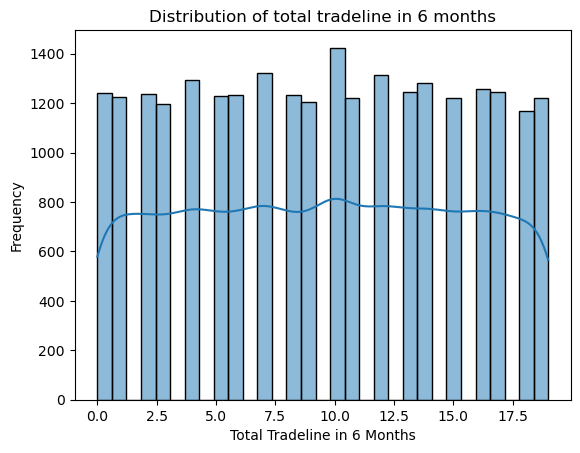

In [54]:
sns.histplot(data=tradeline['Total_Tradelines_6m_In'], kde=True)
plt.ylabel("Frequency")
plt.xlabel("Total Tradeline in 6 Months")
plt.title("Distribution of total tradeline in 6 months")
plt.show()

In [55]:
"""
KDE line: Shows the smoothed distribution, with a slight peak around 10 tradelines.
Conclusion: Clients are fairly evenly distributed across tradeline counts, with no obvious strong skewness or extreme concentration.

"""

'\nKDE line: Shows the smoothed distribution, with a slight peak around 10 tradelines.\nConclusion: Clients are fairly evenly distributed across tradeline counts, with no obvious strong skewness or extreme concentration.\n\n'

In [56]:
#Analyze the Distribution of Total_Enquiry_6m_In.


enq_col = enquiry['Total_Enquiry_6m_In']
print("mean", enq_col.mean())
print("median", enq_col.median())
print("Standard Deviation", col.std())
print("skwness", col.skew())

mean 7.041469387755102
median 7.0
Standard Deviation 5.720602084564762
skwness -0.0027996914797342436


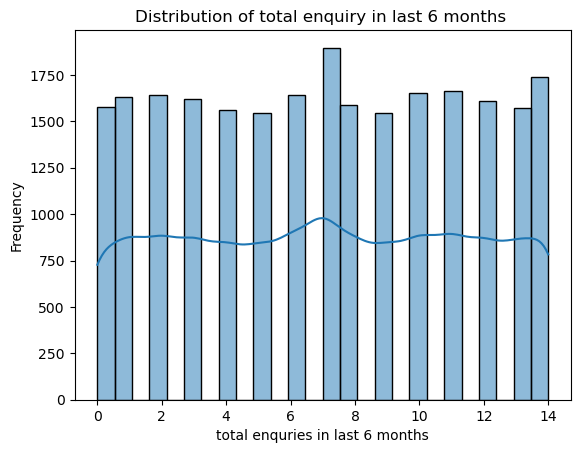

In [57]:
sns.histplot(data= enquiry['Total_Enquiry_6m_In'], kde=True)
plt.title("Distribution of total enquiry in last 6 months ")
plt.ylabel("Frequency")
plt.xlabel("total enquries in last 6 months")
plt.show()

In [58]:
# Distribution of Loan Applications (Applied)

applied = (base['Applied']>0).mean()*100
non_applied = (base['Applied']==0).mean()*100


print("applied:", round(applied, 2))
print("non applied:", round(non_applied,2))

applied: 79.7
non applied: 20.3


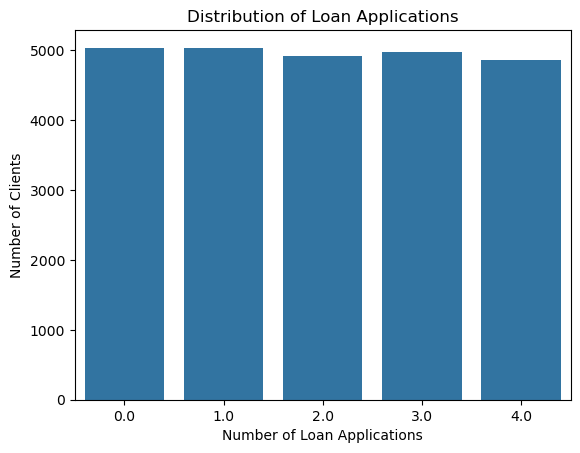

In [59]:
sns.countplot(data=base, x='Applied')
plt.xlabel("Number of Loan Applications")
plt.ylabel("Number of Clients")
plt.title("Distribution of Loan Applications")
plt.show()

In [60]:
#Q4: Analyze the Loan Approval Rate.

ap_applied = (base['Approved']>0).mean()*100
non_ap_applied= (base['Approved']==0).mean()*100


print("approved :", round(ap_applied, 2))
print("not approved:", round(non_ap_applied,2))

approved : 63.9
not approved: 36.1


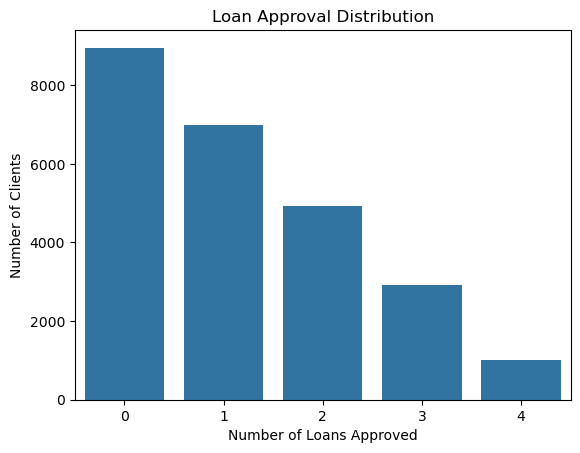

In [61]:
sns.countplot(data=base, x='Approved')
plt.xlabel("Number of Loans Approved")
plt.ylabel("Number of Clients")
plt.title("Loan Approval Distribution")
plt.show()


In [62]:
#Examine the Distribution of Max_Trade_3m_Out.

Mean: 10471.49164
Median: 10429.0
Standard Deviation: 5498.743149376866
Outliers: 0


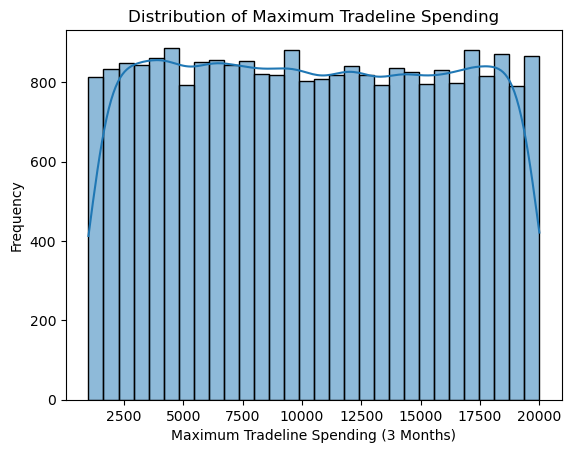

In [63]:
col = tradeline['Max_Trade_3m_Out']

print("Mean:", col.mean())
print("Median:", col.median())
print("Standard Deviation:", col.std())

Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR = Q3 - Q1

LB = Q1 - 1.5 * IQR
UB = Q3 + 1.5 * IQR

print("Outliers:", ((col < LB) | (col > UB)).sum())

sns.histplot(data=tradeline, x='Max_Trade_3m_Out', bins=30, kde=True)
plt.xlabel("Maximum Tradeline Spending (3 Months)")
plt.ylabel("Frequency")
plt.title("Distribution of Maximum Tradeline Spending")
plt.show()

In [64]:
"""
The clients appear to be distributed fairly evenly across the spending range of approximately 1,000–20,000. 
There is no obvious concentration in one spending range.

One important point: This unusually uniform pattern is worth checking against the raw data. 
Also, zero IQR outliers means no values exceeded the calculated boundaries; 
it doesn't necessarily mean there are no unusual spending patterns.
"""

"\nThe clients appear to be distributed fairly evenly across the spending range of approximately 1,000–20,000. \nThere is no obvious concentration in one spending range.\n\nOne important point: This unusually uniform pattern is worth checking against the raw data. \nAlso, zero IQR outliers means no values exceeded the calculated boundaries; \nit doesn't necessarily mean there are no unusual spending patterns.\n"

mean: 18.13032
median: 18.0
standard deviation: 6.279251058633691


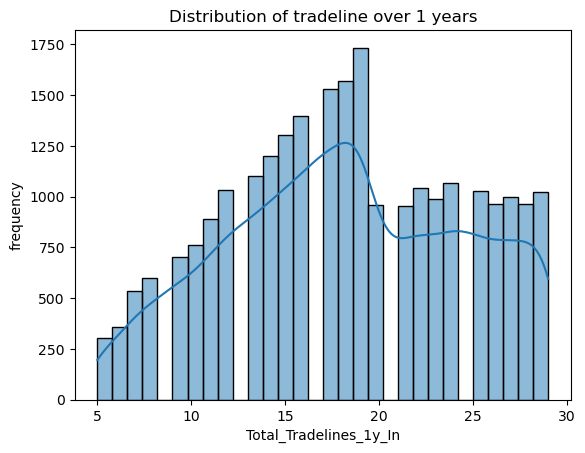

In [65]:
#Identify the Spread of Total_Tradelines_1y_In.

col = tradeline['Total_Tradelines_1y_In']

print("mean:", col.mean())
print("median:", col.median())
print("standard deviation:", col.std())


sns.histplot(data=tradeline, x= 'Total_Tradelines_1y_In' ,kde=True, bins=30)
plt.title("Distribution of tradeline over 1 years")
plt.ylabel("frequency")
plt.show()

mean: 14.372897959183673
median: 14.0
standard deviation: 5.531962071561176


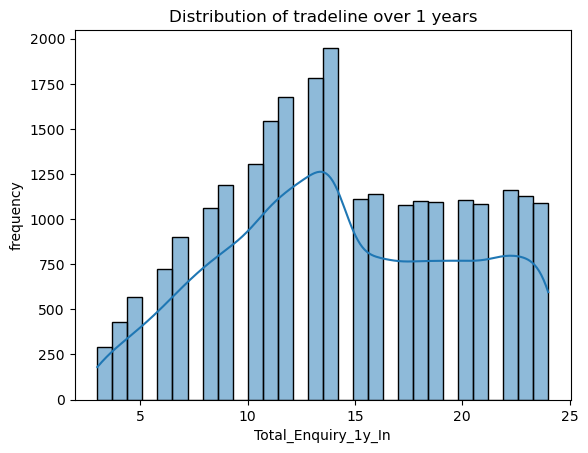

In [66]:
# Distribution of Total_Enquiry_1y_In

col = enquiry['Total_Enquiry_1y_In']

print("mean:", col.mean())
print("median:", col.median())
print("standard deviation:", col.std())


sns.histplot(data=enquiry, x= 'Total_Enquiry_1y_In' ,kde=True, bins=30)
plt.title("Distribution of tradeline over 1 years")
plt.ylabel("frequency")
plt.show()


Stage 4. Data Exploration and Bivariate Analysis


In [67]:
#Q1: Investigating Credit Behavior: Does Higher Credit Activity Lead to More Enquiries?

0.01


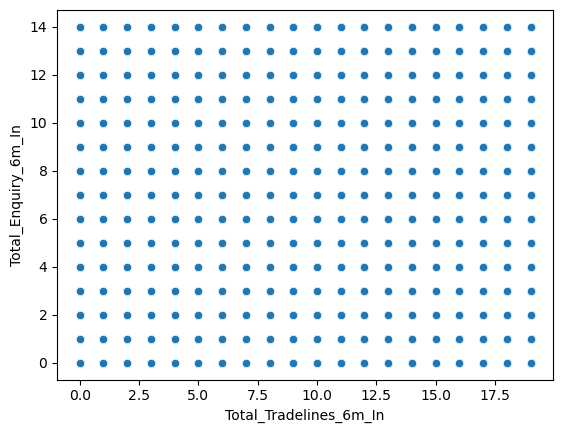

In [68]:
te = pd.merge(tradeline,enquiry, on='Client_ID')

corr = te['Total_Enquiry_6m_In'].corr(te['Total_Tradelines_6m_In'])




sns.scatterplot(data=te, x='Total_Tradelines_6m_In', y='Total_Enquiry_6m_In',  )

print(round(corr, 2))

More Tradeline: 1.97
Fewer Tradeline: 1.99


Text(0, 0.5, 'Averages Application Rates')

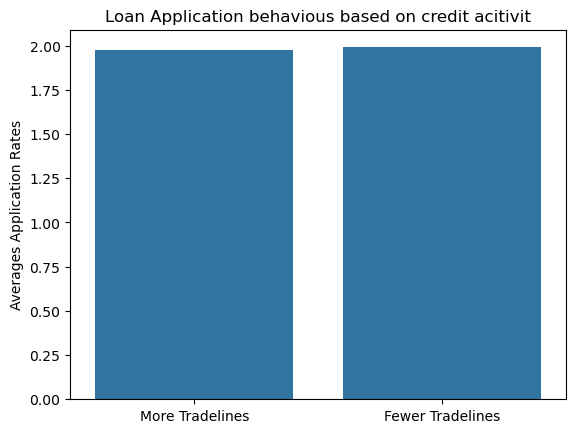

In [69]:
# Exploring Loan Application Behavior: Do Clients with More Tradelines Apply
# More for Loans?

tb = pd.merge(tradeline, base, on='Client_ID', how='inner')

median_value = tb['Total_Tradelines_6m_In'].median()

more = tb[tb['Total_Tradelines_6m_In'] > median_value]
fewer = tb[tb['Total_Tradelines_6m_In'] <= median_value]

print("More Tradeline:", round(more['Applied'].mean(), 2))
print("Fewer Tradeline:", round(fewer['Applied'].mean(), 2))


sns.barplot( x=['More Tradelines', 'Fewer Tradelines'],
    y=[more['Applied'].mean(), fewer['Applied'].mean()])
plt.title("Loan Application behavious based on credit acitivit")
plt.ylabel("Averages Application Rates")


In [70]:
"""
graph shows that clients with fewer tradelines apply for slightly more loans on average.
- More tradelines: Average = 1.97 applications.
- Fewer tradelines: Average = 1.99 applications.
Conclusion: The difference is very small (0.02), 
so tradeline count doesn't appear to have a meaningful relationship with the 
average number of loan applications in this analysis.
"""

"\ngraph shows that clients with fewer tradelines apply for slightly more loans on average.\n- More tradelines: Average = 1.97 applications.\n- Fewer tradelines: Average = 1.99 applications.\nConclusion: The difference is very small (0.02), \nso tradeline count doesn't appear to have a meaningful relationship with the \naverage number of loan applications in this analysis.\n"

-0.003


<Axes: xlabel='Max_Trade_3m_Out', ylabel='Approved'>

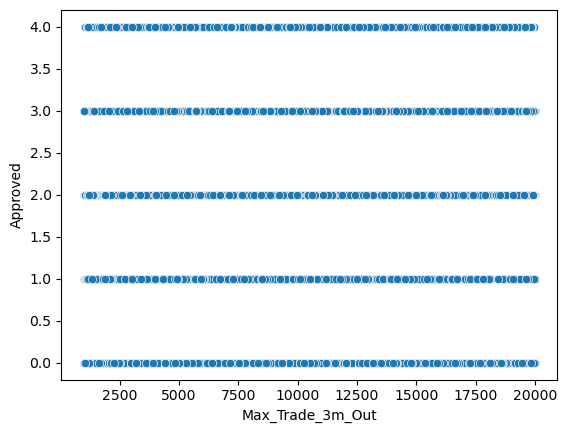

In [71]:
# Understanding Loan Approvals: Does Higher Spending Lead to More Approvals?

app_col = tb[tb['Applied']>0]


corr = app_col['Max_Trade_3m_Out'].corr(app_col['Approved'])
print(round(corr, 3))

sns.scatterplot(data=app_col, x='Max_Trade_3m_Out', y='Approved')


Correlation: 0.0


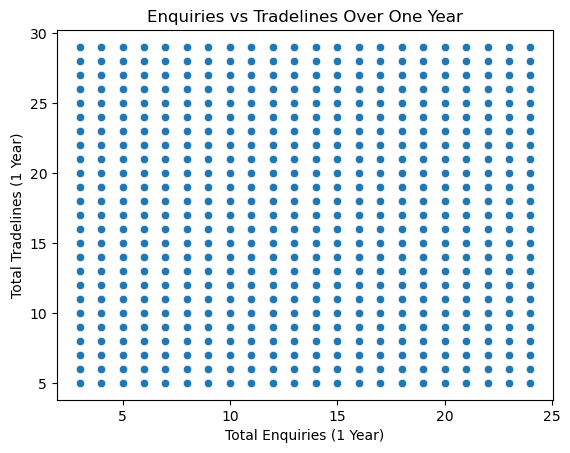

In [72]:
##Exploring Enquiries and Tradeline Behavior Over Time: Do More Enquiries Lead
#to More Tradelines?

merged = enquiry.merge(tradeline, on='Client_ID', how='inner')

# Calculate correlation
corr = merged['Total_Enquiry_1y_In'].corr(
    merged['Total_Tradelines_1y_In']
)

print("Correlation:", round(corr, 2))

# Scatter plot
sns.scatterplot(
    data=merged,
    x='Total_Enquiry_1y_In',
    y='Total_Tradelines_1y_In'
)

plt.xlabel("Total Enquiries (1 Year)")
plt.ylabel("Total Tradelines (1 Year)")
plt.title("Enquiries vs Tradelines Over One Year")
plt.show()

Applied
0.0    0.000000
1.0    0.799960
2.0    1.415497
3.0    1.786318
4.0    2.013803
Name: Approved, dtype: float64


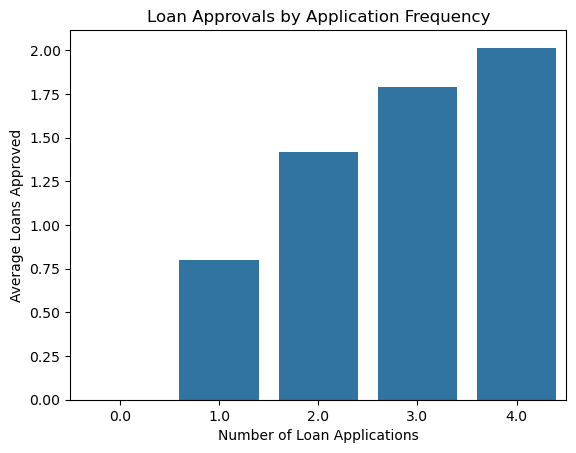

In [73]:
#Analyzing Loan Approvals: Are Clients with More Applications More Likely to BeApproved?


approval_rate = base.groupby('Applied')['Approved'].mean()

print(approval_rate)

# Visualize
sns.barplot(x=approval_rate.index, y=approval_rate.values)
plt.xlabel("Number of Loan Applications")
plt.ylabel("Average Loans Approved")
plt.title("Loan Approvals by Application Frequency")
plt.show()

Correlation: 0.0


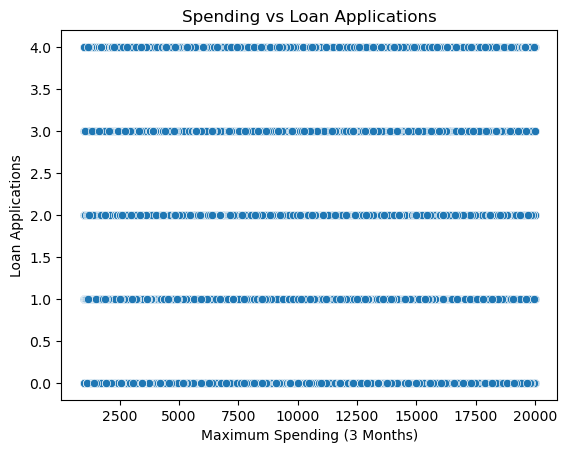

In [74]:
#: Investigating Spending and Loan Applications: Does Higher Spending Encourage Loan Applications?

merged = tradeline.merge(base, on='Client_ID', how='inner')

corr = merged['Max_Trade_3m_Out'].corr(merged['Applied'])

print("Correlation:", round(corr, 2))

sns.scatterplot(
    data=merged,
    x='Max_Trade_3m_Out',
    y='Applied'
)

plt.xlabel("Maximum Spending (3 Months)")
plt.ylabel("Loan Applications")
plt.title("Spending vs Loan Applications")
plt.show()


In [75]:
"""

Stage 4 — Overall Findings
1. Q1 — Credit Activity vs Enquiries: Correlation of 0.01 indicates almost no linear relationship 
between tradelines and enquiries over six months.

2. Q2 — Tradelines vs Loan Applications: Clients with more tradelines averaged 1.97 applications,
compared with 1.99 for clients with fewer tradelines. The difference is negligible.

3. Q3 — Spending vs Loan Approvals: Examines whether higher spending is associated with more loan approvals. 
Your correlation result is needed for a definite finding.

4. Q4 — Enquiries vs Tradelines: Examines whether clients with more enquiries over one year also have more tradelines. 
The correlation result is needed.

5. Q5 — Application Frequency vs Approvals: Compares approval outcomes across clients with different application frequencies. 
The results are needed to identify a pattern.

6. Q6 — Spending vs Loan Applications: Examines whether higher spending is associated with more loan applications.
The correlation result is needed.

Overall conclusion: So far, credit activity shows little relationship with enquiry volume or average loan application counts.
More results are needed to draw conclusions about spending, approvals, and application frequency.
"""

'\n\nStage 4 — Overall Findings\n1. Q1 — Credit Activity vs Enquiries: Correlation of 0.01 indicates almost no linear relationship \nbetween tradelines and enquiries over six months.\n\n2. Q2 — Tradelines vs Loan Applications: Clients with more tradelines averaged 1.97 applications,\ncompared with 1.99 for clients with fewer tradelines. The difference is negligible.\n\n3. Q3 — Spending vs Loan Approvals: Examines whether higher spending is associated with more loan approvals. \nYour correlation result is needed for a definite finding.\n\n4. Q4 — Enquiries vs Tradelines: Examines whether clients with more enquiries over one year also have more tradelines. \nThe correlation result is needed.\n\n5. Q5 — Application Frequency vs Approvals: Compares approval outcomes across clients with different application frequencies. \nThe results are needed to identify a pattern.\n\n6. Q6 — Spending vs Loan Applications: Examines whether higher spending is associated with more loan applications.\nThe c

Stage 5. Feature Engineering


mean approval rate: 0.52


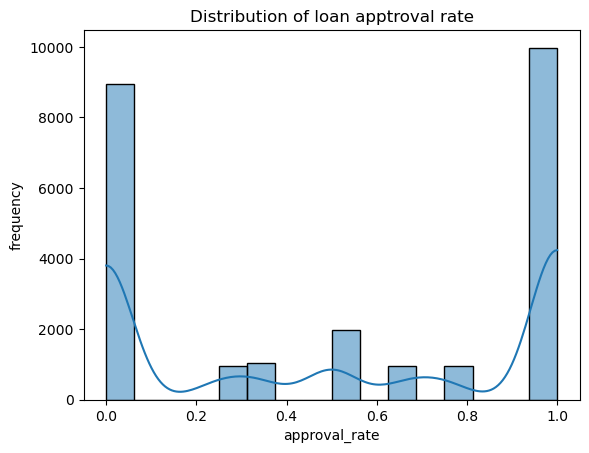

In [76]:
#Assessing the Loan Approval Process: Exploring the Loan Approval Rate

base['approval_rate'] = base['Approved']/base['Applied']

base['approval_rate'] = base['approval_rate'].replace([np.nan, np.inf, -np.inf], 0)

sns.histplot(data= base, x='approval_rate', kde=True )
plt.title("Distribution of loan apptroval rate")
plt.ylabel("frequency")
print("mean approval rate:",round(base['approval_rate'].mean(), 2) )

Average of Utilization rate: 1.0
the corr between them: 0.58


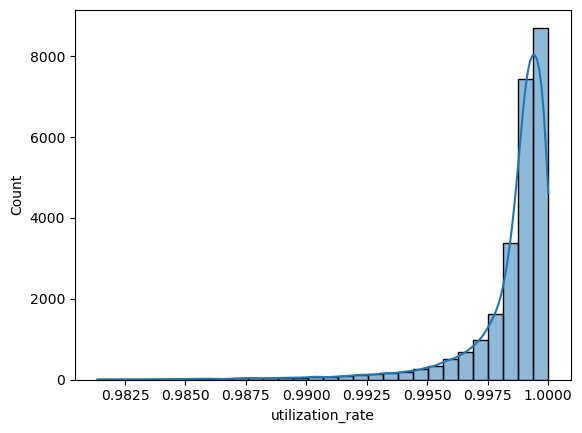

In [77]:
# Understanding Credit Utilization: Evaluating How Clients Use Their Credit.

tradeline['utilization_rate'] = tradeline['Max_Trade_3m_Out']/ (tradeline['Max_Trade_3m_Out'] + tradeline['Total_Tradelines_6m_In'])

tradeline['utilization_rate'] = tradeline['utilization_rate'].replace([np.nan, np.inf, -np.inf], 0)

sns.histplot(x=tradeline['utilization_rate'], kde=True, bins=30)

print("Average of Utilization rate:", round(tradeline['utilization_rate'].mean(), 2))

print("the corr between them:",round(tradeline['utilization_rate'].corr(tradeline['Max_Trade_3m_Out']),2))

Activity_segment
Medium Activity    12689
low Activity        7419
High Activity       4892
Name: count, dtype: int64


Text(0, 0.5, 'Number of Clients')

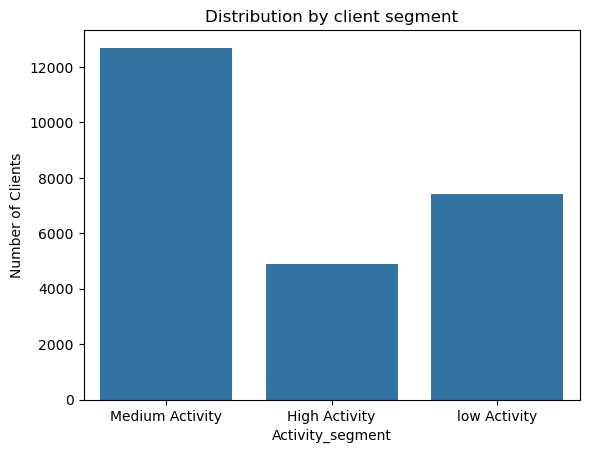

In [85]:
#Q3: Segmenting Clients Based on Credit Activity

tradeline['Activity_segment'] = np.where(tradeline['Total_Tradelines_6m_In']<=5,'low Activity', 
                                         np.where(tradeline['Total_Tradelines_6m_In']<=15, 'Medium Activity', 'High Activity'))

print(tradeline['Activity_segment'].value_counts())

sns.countplot(data=tradeline, x = 'Activity_segment')
plt.title("Distribution by client segment")
plt.ylabel("Number of Clients")

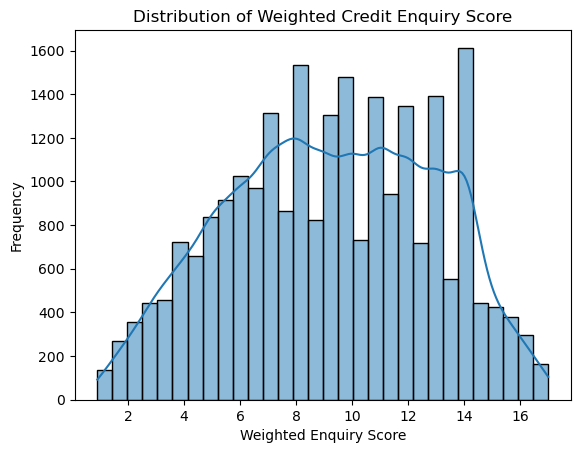

Average weighted enquiry score 9.24


In [100]:
enquiry['weighted_enquiry_score'] = (enquiry['Total_Enquiry_6m_In']*0.7 + enquiry['Total_Enquiry_1y_In']*0.3)

sns.histplot(data=enquiry,x='weighted_enquiry_score',bins=30,kde=True)

plt.xlabel('Weighted Enquiry Score')
plt.ylabel('Frequency')
plt.title('Distribution of Weighted Credit Enquiry Score')
plt.show()
print("Average weighted enquiry score", round(enquiry['weighted_enquiry_score'].mean(), 2))

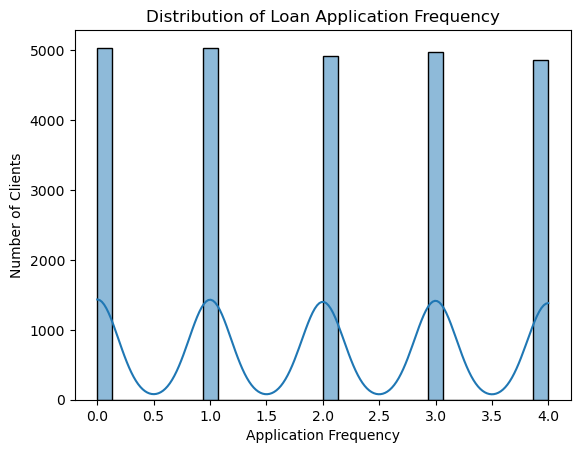

In [102]:
#Examining Loan Application Frequency.

base['Application_Frequency'] = base['Applied']

sns.histplot(data=base, x='Application_Frequency',bins=30, kde=True)

plt.xlabel('Application Frequency')
plt.ylabel('Number of Clients')
plt.title('Distribution of Loan Application Frequency')
plt.show()

risk_profile
Medium risk    16795
High Risk       4811
low risk        2894
Name: count, dtype: int64


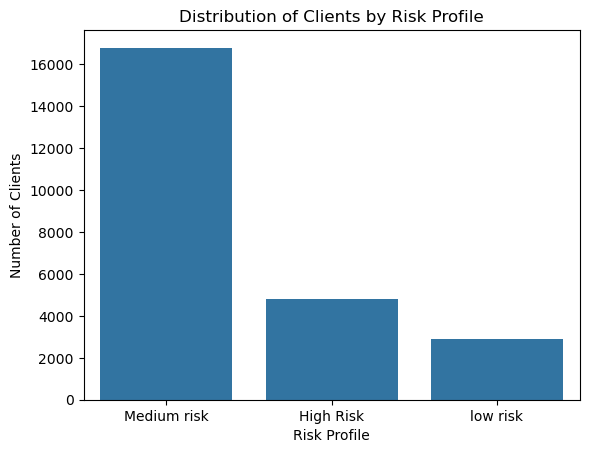

In [106]:
#Evaluating Risk Based on Credit Behavior.
conditions = [
    (te['Total_Tradelines_6m_In'] <= 5) &
    (te['Total_Enquiry_6m_In'] <= 5),

    (te['Total_Tradelines_6m_In'] <= 15) &
    (te['Total_Enquiry_6m_In'] <= 15)]
choices  = ['low risk', 'Medium risk']

te['risk_profile'] = np.select(conditions, choices, default='High Risk')


print(te['risk_profile'].value_counts())

sns.countplot(data=te, x='risk_profile')

plt.xlabel('Risk Profile')
plt.ylabel('Number of Clients')
plt.title('Distribution of Clients by Risk Profile')
plt.show()

Stage 6. Advanced Analysis

Risk_Profile
High Risk      0.52
Low Risk       0.52
Medium Risk    0.53
Name: Approval_Rate, dtype: float64


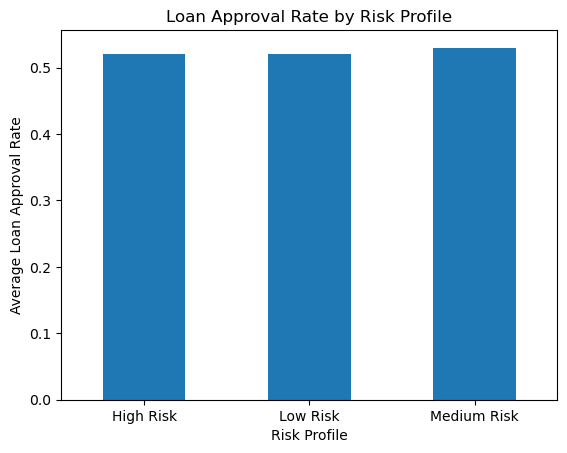

In [114]:
#Identify High-Risk Clients Based on Credit Behavior and Spending.

conditions = [
    (tb['Total_Tradelines_6m_In'] > 10) &
    (tb['Max_Trade_3m_Out'] > 5000),

    (tb['Total_Tradelines_6m_In'].between(5, 10)) &
    (tb['Max_Trade_3m_Out'].between(2000, 5000))
]

choices = ['High Risk', 'Medium Risk']

tb['Risk_Profile'] = np.select(conditions,choices,default='Low Risk')

tb['Approval_Rate'] = ( tb['Approved'] / tb['Applied']).replace([np.nan, np.inf, -np.inf], 0)

approval_by_risk = (tb.groupby('Risk_Profile')['Approval_Rate'].mean().round(2))

print(approval_by_risk)

approval_by_risk.plot(kind='bar')

plt.xlabel('Risk Profile')
plt.ylabel('Average Loan Approval Rate')
plt.title('Loan Approval Rate by Risk Profile')
plt.xticks(rotation=0)
plt.show()

Spending_Group
High Risk      1.19
Low Risk       1.29
Medium Risk    1.18
Name: Approved, dtype: float64


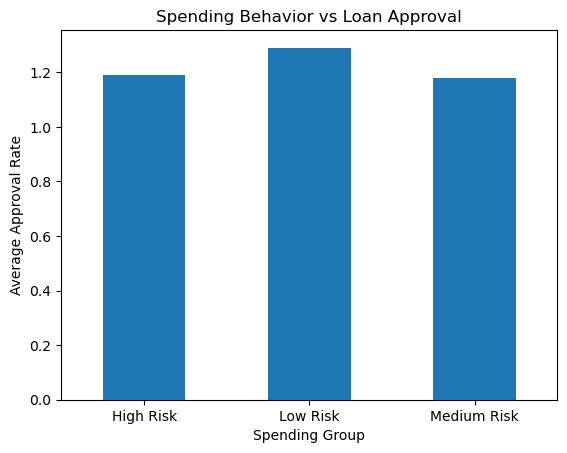

In [118]:
#Explore the Impact of Spending Behavior on Loan Approval.

conditions = [tb['Max_Trade_3m_Out'] <= 2000,(tb['Max_Trade_3m_Out'] > 2000) &(tb['Max_Trade_3m_Out'] <= 5000),
              tb['Max_Trade_3m_Out'] > 5000]

choices = ['Low Risk', 'Medium Risk', 'High Risk']

tb['Spending_Group'] = np.select(conditions, choices, default='Unknown')

approval_by_group = (tb.groupby('Spending_Group')['Approved'].mean().round(2))

print(approval_by_group)

approval_by_group.plot(kind='bar')
plt.xlabel('Spending Group')
plt.ylabel('Average Approval Rate')
plt.title('Spending Behavior vs Loan Approval')
plt.xticks(rotation=0)
plt.show()

Approval rate for high application frequency clients: 1.90
Approval rate for low application frequency clients: 0.73


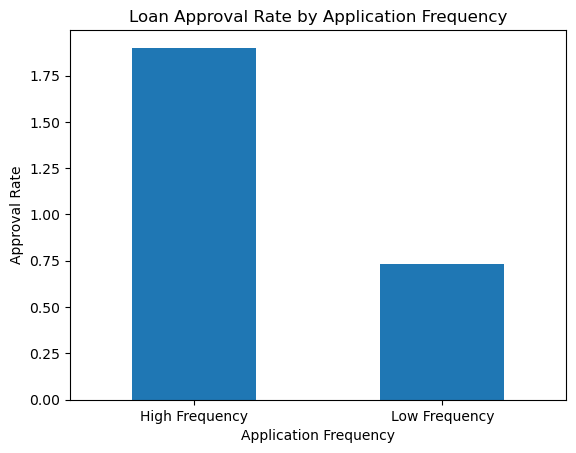

In [120]:
# Identifying Client Segments with High Loan Application Frequency


df['Application_Frequency'] = df['Applied']

median_frequency = df['Application_Frequency'].median()

df['Frequency_Group'] = np.where(
    df['Application_Frequency'] > median_frequency,
    'High Frequency',
    'Low Frequency'
)

# Follow the PDF's expected calculation
approval_rate = (
    df.groupby('Frequency_Group')['Approved']
    .mean()
    .round(2)
)

print(
    f"Approval rate for high application frequency clients: "
    f"{approval_rate['High Frequency']:.2f}"
)
print(
    f"Approval rate for low application frequency clients: "
    f"{approval_rate['Low Frequency']:.2f}"
)

# Plot in the same order as the PDF
approval_rate = approval_rate.reindex(
    ['High Frequency', 'Low Frequency']
)

approval_rate.plot(kind='bar')
plt.xlabel('Application Frequency')
plt.ylabel('Approval Rate')
plt.title('Loan Approval Rate by Application Frequency')
plt.xticks(rotation=0)
plt.show()

Engagement_Group
Engaged Clients         0.65
Less Engaged Clients    0.66
Name: Approval_Rate, dtype: float64


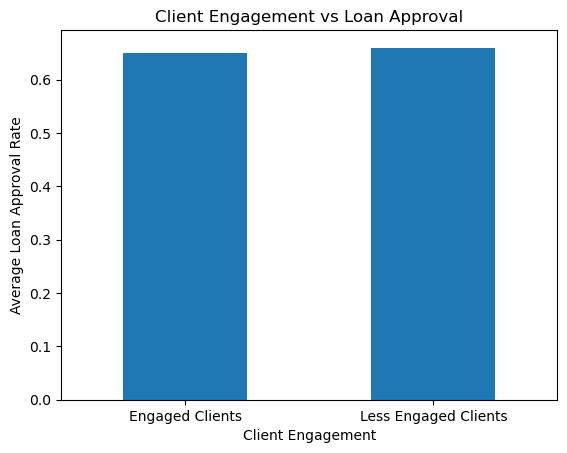

In [123]:
#Investigating the Link Between Loan Approval and Client Engagement.

df = tradeline.merge(enquiry,on='Client_ID',how='inner')
df = df.merge(base,on='Client_ID',how='inner')

# Segment clients based on credit engagement
conditions = [
    (df['Total_Tradelines_6m_In'] > 5) &(df['Total_Enquiry_6m_In'] > 5),(df['Total_Tradelines_6m_In'] <= 5) &(df['Total_Enquiry_6m_In'] <= 5)]

choices = ['Engaged Clients', 'Less Engaged Clients']
df['Engagement_Group'] = np.select(conditions,choices,default='Other')

# Calculate approval rate
df['Approval_Rate'] = np.where(df['Applied'] > 0,df['Approved'] / df['Applied'],np.nan)

# Compare average approval rates
approval_by_engagement = (df[df['Engagement_Group'] != 'Other'].groupby('Engagement_Group')['Approval_Rate'].mean().round(2))

print(approval_by_engagement)

# Visualize
approval_by_engagement.plot(kind='bar')
plt.xlabel('Client Engagement')
plt.ylabel('Average Loan Approval Rate')
plt.title('Client Engagement vs Loan Approval')
plt.xticks(rotation=0)
plt.show()

In [ ]:
"""
Stage 6 moves the analysis beyond simply inspecting columns and distributions. 
It tests how credit behaviour, spending, application frequency and engagement relate to lending outcomes. 

This can help a lending team identify useful segments, assess whether simple risk rules distinguish clients, 
and decide which variables deserve deeper investigation.

The most important analytical lesson is that a difference in approval counts is not necessarily a

difference in approval probability. Segment sizes, application volumes and actual approval rates 
should be evaluated together before making a recommendation.

To complete the analysis with verified results from your data, upload the three source

files (base_file, tradeline_data and enquiry_data) as CSV or Excel files. I can then run 
all five questions against the actual records and give you the calculated findings, charts 
and a final business-insights summary instead of relying on the PDF's reference outputs.
"""